In [1]:
"""
====================================================================================
 Jaynes-Cummings-Hubbard (JCH) Polariton Lattice -- Bosonic Qiskit simulation
====================================================================================

MODEL
-----
    H = sum_i [ wc a_i^dag a_i + (wa/2) Z_i + g (a_i^dag sigma_i^- + a_i sigma_i^+) ]
        - J sum_<i,j> (a_i^dag a_j + a_j^dag a_i)

    a_i     : bosonic (cavity photon) annihilation op at site i, Fock-truncated at CUTOFF
    sigma_i : two-level atom (qubit) at site i, sigma^- = |g><e|
    g       : on-site Jaynes-Cummings (light-matter) coupling  -> polariton formation
    J       : nearest-neighbour photon hopping (Bose-Hubbard-like tunneling)
              this is what lets polaritons delocalize/entangle across the lattice

ENCODING (bosonic-qiskit / c2qa)
---------------------------------
    site i  =  1 qumode (cavity, Fock-truncated, computational basis |k> == Fock |k>)
             + 1 physical qubit (atom)
    qumode  -> m = ceil(log2(CUTOFF)) physical qubits
    qubit layout on the circuit (registration order): all qumode qubits first
    (site 0 qumode, site 1 qumode, ... ) then all atom qubits (site 0 atom, ...).
    -> verify with `[ (q, i) for i, q in enumerate(circuit.qubits) ]` if your
       installed c2qa version differs; this is the same self-discovery trick
       used before with `[m for m in dir(circuit) if m.startswith('cv_')]`.

EVOLUTION
---------
    1st-order Trotter step:
        U(dt) ~ [prod_i exp(-i H_JC,i dt)] . [prod_<i,j> exp(-i H_hop,ij dt)]
    (on-resonance wc=wa assumed by default -> no extra free-phase gates needed;
     set DETUNING != 0 below to switch that term back on)

SCALABILITY  (i5-13420H laptop, ~16-32 GB RAM)
------------------------------------------------
    Full statevector cost = 2^(N*(m+1)) amplitudes -> exponential in N, unusable
    beyond ~13-14 sites even at CUTOFF=2. To reach N=10-20 this script:

      1) defaults to CUTOFF=2 (0/1 photon per site -> m=1 qubit/qumode). This is
         the "single-excitation-manifold" truncation, standard for JCH physics
         when g,J << photon energy so multi-photon-per-site processes are rare.
         Bump CUTOFF to 3 or 4 for richer bosonic nonlinearity, but then keep
         N small (<=6-8) -- see the printed qubit count at runtime.

      2) uses AerSimulator(method="matrix_product_state") (USE_MPS=True). MPS
         cost scales with the chain's actual entanglement (bond dimension),
         not with 2^N, and is efficient for the short-range, short-time JCH
         dynamics here.

      3) NEVER materializes the full global statevector/density matrix. Every
         observable (site occupancy, entanglement entropy) is obtained with
         `circuit.save_density_matrix(qubits=<small subset>, label=...)`,
         which Aer's MPS backend evaluates by tracing out the rest of the
         chain internally -- the returned matrix is always tiny (a few
         qubits), regardless of N.

      4) Entanglement entropy is computed for a SINGLE SITE (or small block)
         vs. the rest of the chain. For a pure global state, S_A = S_B, so
         this equals the "half-chain cut" entropy value but costs O(1)
         instead of O(2^N) -- a full half-chain density matrix would again be
         exponential in N and defeats the point of using MPS. An optional,
         separate half-chain block is included at the bottom, clearly marked
         as only safe for small N with the statevector backend.

pip install:  qiskit  qiskit-aer  matplotlib  numpy
              pip install git+https://github.com/C2QA/bosonic-qiskit.git
              
"""

'\n====================================================================================\n Jaynes-Cummings-Hubbard (JCH) Polariton Lattice -- Bosonic Qiskit simulation\n====================================================================================\n\nMODEL\n-----\n    H = sum_i [ wc a_i^dag a_i + (wa/2) Z_i + g (a_i^dag sigma_i^- + a_i sigma_i^+) ]\n        - J sum_<i,j> (a_i^dag a_j + a_j^dag a_i)\n\n    a_i     : bosonic (cavity photon) annihilation op at site i, Fock-truncated at CUTOFF\n    sigma_i : two-level atom (qubit) at site i, sigma^- = |g><e|\n    g       : on-site Jaynes-Cummings (light-matter) coupling  -> polariton formation\n    J       : nearest-neighbour photon hopping (Bose-Hubbard-like tunneling)\n              this is what lets polaritons delocalize/entangle across the lattice\n\nENCODING (bosonic-qiskit / c2qa)\n---------------------------------\n    site i  =  1 qumode (cavity, Fock-truncated, computational basis |k> == Fock |k>)\n             + 1 physical q

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import DensityMatrix, entropy
import bosonic_qiskit as c2qa

# ------------------------------- USER PARAMETERS ------------------------------------
N_SITES   = 8        # lattice sites. Try 10-20 with CUTOFF=2 + USE_MPS=True,
                       # or 6-8 with CUTOFF=3/4.
CUTOFF    = 2          # Fock truncation per qumode (photon numbers 0..CUTOFF-1)
USE_MPS   = True       # matrix_product_state backend (needed for N>~12)

wc        = 1.0        # cavity frequency
wa        = 1.0        # atom frequency
DETUNING  = wc - wa    # set wc != wa above if you want detuned free-phase gates
g         = 0.35        # Jaynes-Cummings coupling
J         = 0.15        # inter-site photon hopping

DT        = 0.05       # Trotter step size
N_STEPS   = 5000         # -> T_max = N_STEPS * DT

INIT_SITE = N_SITES // 2   # site that starts with 1 photon; rest vacuum, atoms in |g>
ENT_SITE  = INIT_SITE       # site used for the scalable entanglement-entropy cut
# --------------------------------------------------------------------------------------

m = int(np.ceil(np.log2(CUTOFF)))          # qubits per qumode
total_qubits = N_SITES * (m + 1)
print(f"[info] N_SITES={N_SITES}, CUTOFF={CUTOFF} -> {m} qubit(s)/qumode, "
      f"{total_qubits} total qubits")

qmr = c2qa.QumodeRegister(num_qumodes=N_SITES, num_qubits_per_qumode=m)
qr  = qiskit.QuantumRegister(N_SITES, name="atom")
circuit = c2qa.CVCircuit(qmr, qr)

# ------------------------------- initial state ---------------------------------------
# 1) initial state — flip atoms to |1>, the TRUE ground state under cv_jc's convention
for i in range(N_SITES):
    circuit.cv_initialize(1 if i == INIT_SITE else 0, qmr[i])
    circuit.x(qr[i])              # <-- ADD: was implicitly starting every atom "excited"


# ------------------------------- qubit-index bookkeeping ------------------------------
def qumode_qubits(site):
    return list(range(site * m, site * m + m))

def atom_qubit(site):
    return N_SITES * m + site

def site_block(site):
    return qumode_qubits(site) + [atom_qubit(site)]

# ------------------------------- local operators (dense, tiny) ------------------------
def number_op_mode():
    dim = 2 ** m
    return np.diag([min(k, CUTOFF - 1) for k in range(dim)]).astype(complex)

# 2) occupancy operator — flip which computational state counts as "excited"
def number_op_atom():
    return np.diag([1.0, 0.0]).astype(complex)   # <-- was [0.0, 1.0]

N_MODE_OP = number_op_mode()
N_ATOM_OP = number_op_atom()
# total (polariton) number op on one site's block == kron(n_mode, I2) + kron(I_dimmode, n_atom)
I_MODE = np.eye(2 ** m)
I_ATOM = np.eye(2)
N_SITE_OP = np.kron(N_ATOM_OP, I_MODE) + np.kron(I_ATOM, N_MODE_OP)

# N_SITE_OP = np.kron(N_MODE_OP, np.eye(2)) + np.kron(I_MODE, N_ATOM_OP)

# ------------------------------- build circuit + save instructions --------------------
def append_trotter_step(circ):
    # 1) on-site Jaynes-Cummings coupling g(a^dag sigma- + a sigma+)
    for i in range(N_SITES):
        circ.cv_jc(g * DT, 0.0, qmr[i], qr[i])
        circ.barrier()

        # NOTE: check exact cv_jc(theta, qumode, qubit[, phi]) signature/sign
        # against your installed c2qa version with:
        #   [meth for meth in dir(circ) if meth.startswith('cv_')]
        # If cv_jc isn't present, build it from cv_c_d / conditional rotations.

    # 2) optional detuned free precession
    if abs(DETUNING) > 1e-12:
        for i in range(N_SITES):
            circ.cv_r(wc * DT, qmr[i])
            circ.rz(wa * DT, qr[i])
            circ.barrier()

    # 3) nearest-neighbour photon hopping (beamsplitter realizes a_i^dag a_j + h.c.)
    for i in range(N_SITES - 1):
        circ.cv_bs(-J * DT, qmr[i], qmr[i + 1])
        circ.barrier()
        # NOTE: verify cv_bs(theta, qumode_a, qumode_b) sign/phase convention
        # the same way as above; an overall sign error just flips hopping
        # direction phase and won't change occupancy/entropy magnitudes.

#circuit.draw("mpl", style={"backgroundcolor": "#eeeeee", "dpi": 150})



[info] N_SITES=8, CUTOFF=2 -> 1 qubit(s)/qumode, 16 total qubits


In [9]:
labels_occ = []   # (t_index, site) -> label
labels_ent = []   # t_index -> label

for site in range(N_SITES):
    lbl = f"occ_s{site}_t0"
    circuit.save_density_matrix(qubits=site_block(site), label=lbl)
    labels_occ.append((0, site, lbl))
lbl = "ent_t0"
circuit.save_density_matrix(qubits=site_block(ENT_SITE), label=lbl)
labels_ent.append((0, lbl))

for t in range(1, N_STEPS + 1):
    append_trotter_step(circuit)
    for site in range(N_SITES):
        lbl = f"occ_s{site}_t{t}"
        circuit.save_density_matrix(qubits=site_block(site), label=lbl)
        labels_occ.append((t, site, lbl))
    lbl = f"ent_t{t}"
    circuit.save_density_matrix(qubits=site_block(ENT_SITE), label=lbl)
    labels_ent.append((t, lbl))

#circuit.draw("mpl",scale=0.7,fold=100, style={"backgroundcolor": "#eeeeee", "dpi": 150})


In [10]:
# ------------------------------- run ---------------------------------------------------
backend = AerSimulator(method="matrix_product_state" if USE_MPS else "statevector")
tcirc = transpile(circuit, backend)
result = backend.run(tcirc).result()
print(result.results[0].metadata.get("method"))
data = result.data(0)

# ------------------------------- post-process -----------------------------------------
occupancy = np.zeros((N_SITES, N_STEPS + 1))
for (t, site, lbl) in labels_occ:
    rho = np.asarray(data[lbl])
    occupancy[site, t] = np.real(np.trace(rho @ N_SITE_OP))

ent_S = np.zeros(N_STEPS + 1)
for (t, lbl) in labels_ent:
    rho = np.asarray(data[lbl])
    dm = DensityMatrix(rho)
    ent_S[t] = entropy(dm, base=2)  # von Neumann entropy of ENT_SITE vs rest of chain

times = np.arange(N_STEPS + 1) * DT

c:\Users\LENOVO\OneDrive\Desktop\bosonic Qiskit\.venv\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
c:\Users\LENOVO\OneDrive\Desktop\bosonic Qiskit\.venv\Lib\site-packages\scipy\sparse\linalg\_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


matrix_product_state


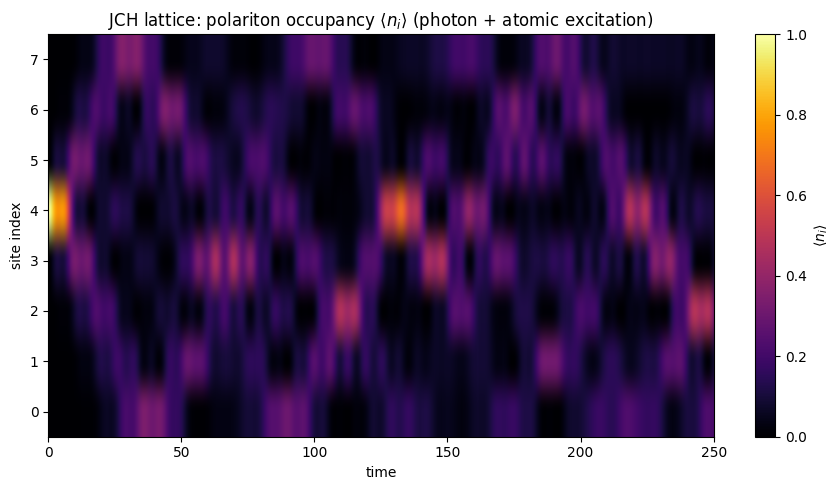

In [11]:
fig1, ax1 = plt.subplots(figsize=(9, 5))
im = ax1.imshow(occupancy, aspect="auto", origin="lower",
                 extent=[times[0], times[-1], -0.5, N_SITES - 0.5], cmap="inferno")
ax1.set_xlabel("time")
ax1.set_ylabel("site index")
ax1.set_title("JCH lattice: polariton occupancy $\\langle n_i \\rangle$ (photon + atomic excitation)")
fig1.colorbar(im, ax=ax1, label=r"$\langle n_i \rangle$")
fig1.tight_layout()
#fig1.savefig(f"jch_occupancy_heatmap{N_SITES}.png", dpi=150)
plt.show()

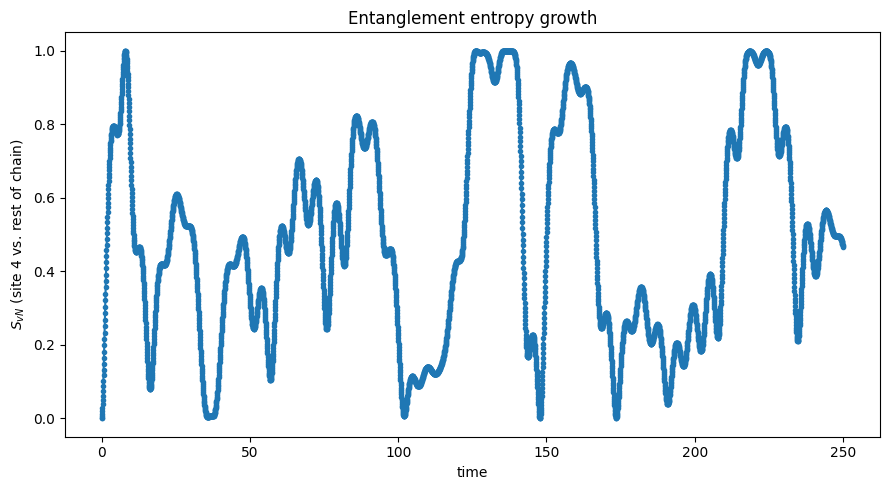

In [13]:
# ------------------------------- plot2 --------------------------------------------------

fig2, ax2 = plt.subplots(figsize=(9,5))
ax2.plot(times, ent_S, marker="o", ms=3)
ax2.set_xlabel("time")
ax2.set_ylabel(f"$S_{{vN}}$ (site {ENT_SITE} vs. rest of chain)")
ax2.set_title("Entanglement entropy growth")
fig2.tight_layout()
#fig2.savefig(f"jch_entanglement_entropy{N_SITES}.png", dpi=150)

plt.show()

